In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [21]:
df = pd.read_csv('uber.csv')

print(df.head())
print(df.shape)
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [22]:
df = df.dropna()
df = df.drop_duplicates()

df = df[(df['fare_amount'] > 0)]
df = df[(df['passenger_count'] > 0) & (df['passenger_count'] <= 6)]

print("Cleaned data:", df.shape)

Cleaned data: (199268, 9)


In [23]:
cols = ['fare_amount', 'pickup_longitude', 'pickup_latitude',
        'dropoff_longitude', 'dropoff_latitude', 'passenger_count']

# Detect outliers
for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print(col, "Outliers:", ((df[col] < lower) | (df[col] > upper)).sum())

# Remove outliers
for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

print("Shape after removing outliers:", df.shape)

fare_amount Outliers: 17121
pickup_longitude Outliers: 13520
pickup_latitude Outliers: 9384
dropoff_longitude Outliers: 14153
dropoff_latitude Outliers: 12095
passenger_count Outliers: 22552
Shape after removing outliers: (147449, 9)


pickup_longitude    -0.052471
pickup_latitude     -0.076403
dropoff_longitude   -0.022858
dropoff_latitude    -0.094248
passenger_count      0.018178
fare_amount          1.000000
Name: fare_amount, dtype: float64


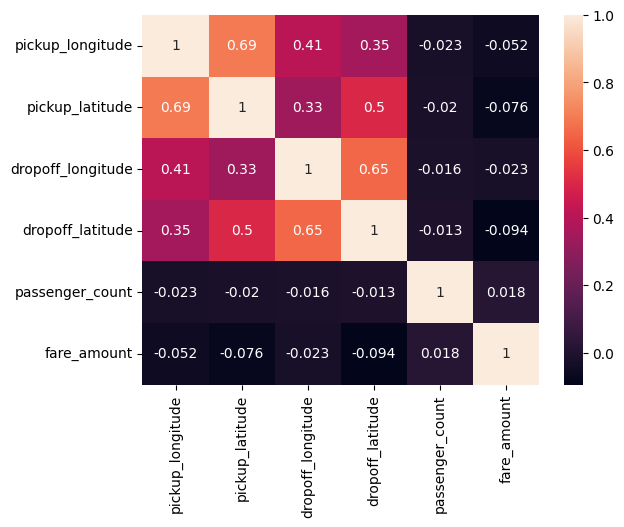

In [24]:
features = ['pickup_longitude', 'pickup_latitude',
            'dropoff_longitude', 'dropoff_latitude',
            'passenger_count']

corr = df[features + ['fare_amount']].corr()

print(corr['fare_amount'])

sns.heatmap(corr, annot=True)
plt.show()

In [ ]:
X = df[features]
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)

rf = RandomForestRegressor(n_estimators=10, max_depth=5, random_state=42)
rf.fit(X_train, y_train)

print("Models trained successfully")

Models trained successfully


Linear Regression
R2 Score: 0.014541287769266997
MSE: 14.567609501597682
Random Forest
R2 Score: 0.29116795363961956
MSE: 10.478357261890748


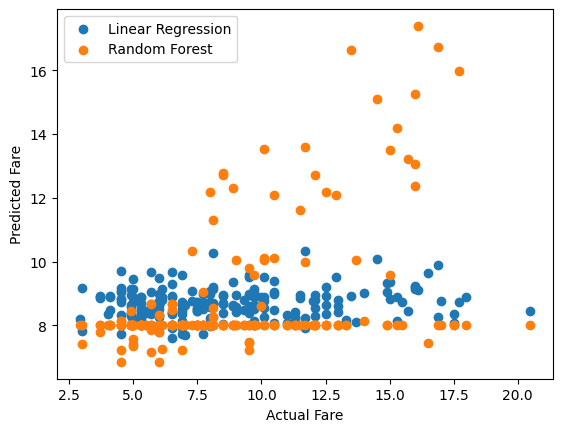

In [30]:
for name, model in [('Linear Regression', lr), ('Random Forest', rf)]:
    pred = model.predict(X_test)
    print(name)
    print("R2 Score:",r2_score(y_test, pred))
    print("MSE:",mean_squared_error(y_test, pred))
    plt.scatter(y_test[:200], pred[:200], label=name)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.legend()
plt.show()